# Comparing tTEM and diffTEM

In [48]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import plog

from anemone.experiment import *
from math import log10

In [49]:
from libaarhusxyz import GEX

In [50]:
gex = GEX("C:/Users/au646858/Downloads/TX11_3x3_1_turn.gex")
# gex = GEX(r"Z:\Projects_tTEM\2021_tTEM_NoerreVosborg\tTEM\Data\20210217_TX08_tTEM33_RC20_CalATV.gex")

header [General] parsed
header [Channel1] parsed
header [Channel2] parsed


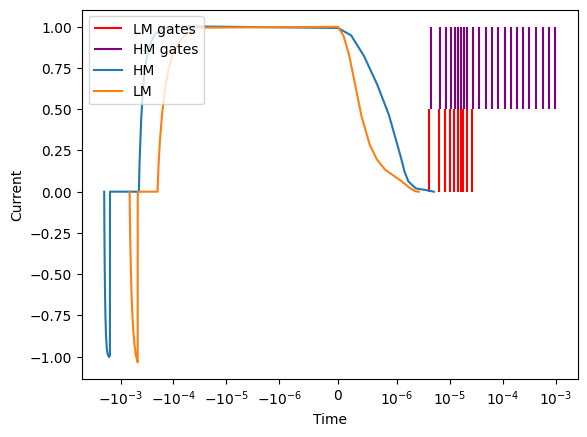

In [51]:
gex.plot()

In [52]:
lmgates = torch.from_numpy(gex.gate_times('Channel1')[1:,0])
hmgates = torch.from_numpy(gex.gate_times('Channel2')[1:,0])

LMwv = Waveform(gex.General['WaveformLMPoint'][:, 0], gex.General['WaveformLMPoint'][:, 1])
HMwv = Waveform(gex.General['WaveformHMPoint'][:, 0], gex.General['WaveformHMPoint'][:, 1])

In [53]:
class DualMoment:
    def __init__(self, source, receiver, times, filterfunc, waveforms):
        self.source = source
        self.receiver = receiver
        self.times = times
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(times[0].device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(times[0].device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z
        self.pfield_dz = torch.abs(self.srcz-self.rz)
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)
                
        self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times[0].device)
        self.waveforms = waveforms
        self.tmin = min(self.times[0].min(), self.times[1].min())
        self.tmax = max(self.times[0].max(), self.times[1].max())

        self.filterfunc = filterfunc
        self.device = times[0].device
        self.waveforms = []
        for waveform in waveforms:
            if waveform is not None:
                if waveform.time.max()<self.tmin:
                    self.tmin += -waveform.time.max()
                self.tmax += -waveform.time.min()
                waveform.time = waveform.time.to(self.device)
                waveform.amplitude = waveform.amplitude.to(self.device)
                waveform.d2wdt2 = waveform.d2wdt2.to(self.device)
            self.waveforms.append(waveform)


    def forward(self):
        def frq_integrand(f):
            omega = c.twopi*f[None,:,None]

            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                lmb = wave_length[None, None, :]
                tmp_u0 = u0(omega, lmb)
                cRTE = rte(self.sigma, self.thick, omega, lmb)
                intg = torch.exp(-tmp_u0*self.pfield_dz)+cRTE*torch.exp(-tmp_u0*self.sfield_dz)
                intg *= lmb**2 / tmp_u0
                intg /= -1j*omega

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                return torch.squeeze(intg/c.fourpi)

            hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=10, range=(self.rmin, self.rmax), device=self.device)
            return integrate_around_loop(self.source, self.receiver, hkl1)#/1j

        ift = invFourier(frq_integrand, smp_per_decade=16)
        t,dbdt=ift.range(self.tmin, self.tmax)
        cbft = CubicSpline(t,dbdt, transform=torch.log10)
        
        dbdts = []
        for i in range(2):
            t = self.times[i]
            t_eval = t[:, None] - self.waveforms[i].time[None, :]
            resp_step = cbft(t_eval)
            dbdt = resp_step @ self.waveforms[i].d2wdt2
            dbdts.append(dbdt.real.T)
        return torch.concatenate(dbdts).T

    def __call__(self, sigma, thickness):
        self.sigma = ((sigma+0j)[..., None, None]).to(self.device)
        if sigma.ndim > thickness.ndim:
            thickness = thickness[:, None]
        self.thick = ((thickness+0j)[..., None, None]).to(self.device)
        return self.forward().real*c.mu0
    

c:\users\au646858\onedrive - aarhus universitet\documents\repositories\anemone\src\anemone\experiment\experiment.py:105: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return tc.tensor(overall_min)
C:\Users\au646858\AppData\Local\Temp\ipykernel_32732\1508960272.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times[0].device)


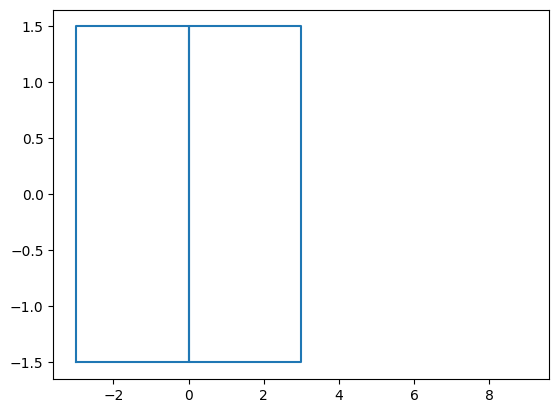

In [54]:
recfilters = FilterChain([
    # ButterworthFilter(6.79e5),
    ButterworthFilter(4.2e5),
    # ButterworthFilter(4.2e5)
])

tx = Loop.square(3, z=0.97)
tx = Loop.fig8(3, z=0.97)
rx = Receiver(x=9, z=0.43)

plt.figure()
plt.plot(tx.x, tx.y)
plt.plot(rx.x, rx.y)

fwr = DualMoment(tx, rx, [lmgates, hmgates], recfilters, [LMwv, HMwv])

In [55]:
res = np.array([10, 200, 20])
#res = np.array([200, 10, 50])
thick1 = np.linspace(0.25, 5, 25)

In [56]:
sigma = torch.from_numpy(1./res)
thick = torch.tensor([5, 10])
data = fwr(sigma, thick)

In [57]:
thick_stack = np.vstack([thick1, np.ones_like(thick1)*10])
sigma = torch.from_numpy(1./res)[:, None]
thick = torch.from_numpy(thick_stack)

lgs = [plog.Log(np.log10(res), np.array([0, thk, thk+10]), np.array([thk,thk+10, 20]), 'rho', units='$\\Omega m$') for thk in thick1]

In [58]:
def compute_std(t_gates, data_val, noise_slope_exponent=-0.5, noise_level_at_1ms=1e-8, moment=1, relative_noise=0.03):
    b = noise_level_at_1ms/(1e-3**noise_slope_exponent)
    abs_noise = b*(t_gates**noise_slope_exponent)
    y = data_val*moment
    std_rel = abs_noise/y
    std_tot = np.sqrt(std_rel**2 + relative_noise**2)
    return std_tot

In [59]:
cmdl = CondModel.starting_model(3)
inv = torchInv(dbdt, dbdt*dbdt_err, cmdl, fwr)

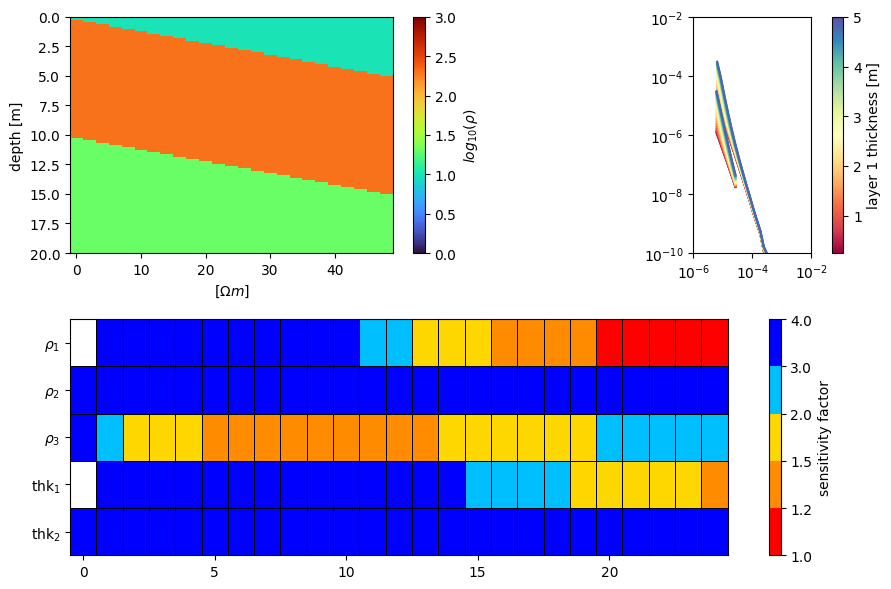

In [60]:
cm = plt.get_cmap('Spectral')

fig,axd = plt.subplot_mosaic('AB\nCC', figsize=(9,6))
axs = list(axd.values())

nanmat = np.zeros((2,2))
nanmat[:,:] = np.nan
pcm=axs[1].imshow(nanmat, cmap='Spectral', vmin=thick1.min(), vmax=thick1.max(), origin='lower')
plt.colorbar(pcm, ax=axs[1], label='layer 1 thickness [m]')

tcat = torch.cat(fwr.times)

for i,lg in enumerate(lgs):
    sigma = torch.from_numpy(1./res)
    thick = torch.tensor([thick1[i], 10])
    dbdt = fwr(sigma, thick)
    dbdt_err = compute_std(tcat, dbdt)
    inv = torchInv(dbdt, dbdt*dbdt_err*0.1, cmdl, fwr)
    m_true = CondModel(sigma, thick)


    axs[1].loglog(fwr.times[0].numpy(), np.abs(dbdt[:len(fwr.times[0])].numpy()*3), color=cm(i/len(lgs)))
    axs[1].loglog(fwr.times[1].numpy(), np.abs(dbdt[len(fwr.times[0]):].numpy()*30), color=cm(i/len(lgs)))
    ax,pcm=lg.plot(ax=axs[0], dx=2, x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[0].set_ylim(20,0)
    
    sensitivity_analysis(inv, m_true, ax=axs[2], x_offset=i, cbar=i==22)


axs[-1].set_ylim(5,0)
plt.colorbar(pcm, ax=ax, label='$log_{10}\\left(\\rho\\right)$', format='%.1f')
ax.set_ylabel('depth [m]')

axs[1].set_xlim(1e-6, 1e-2); axs[1].set_ylim(1e-10, 1e-2)
axs[1].set_aspect('equal')
plt.tight_layout()

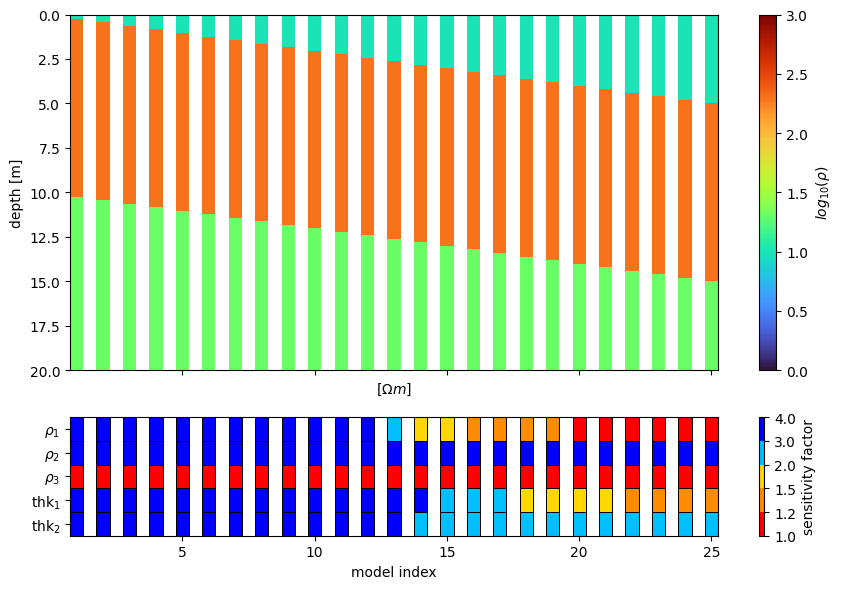

In [61]:
cm = plt.get_cmap('Spectral')

fig,axs = plt.subplots(2,1, sharex=True, figsize=(9,6), height_ratios=[3,1])
nanmat = np.zeros((2,2))
nanmat[:,:] = np.nan
tcat = torch.cat(fwr.times)
lm_slice = slice(0, len(fwr.times[0]))
hm_slice = slice(len(fwr.times[0]), None)

for i,lg in enumerate(lgs):
    sigma = torch.from_numpy(1./res)
    thick = torch.tensor([thick1[i], 10])
    dbdt = fwr(sigma, thick)
    dbdt_err = compute_std(tcat, dbdt, moment=3*9)
    dbdt_err[hm_slice] = compute_std(tcat, dbdt, moment=30*9)[hm_slice]
    inv = torchInv(dbdt, dbdt*dbdt_err, cmdl, fwr)
    m_true = CondModel(sigma, thick)


    ax,pcm=lg.plot(ax=axs[0], dx=1., x_offset=i*2, cmap='turbo', vmin=0, vmax=3)
    axs[0].set_ylim(20,0)

    sensitivity_analysis(inv, m_true, ax=axs[1], x_offset=i*2, cbar=i==22)

ax = axs[0]
axs[1].set_xlabel('model index')
axs[1].set_xticks(range(8, 51, 10))
axs[1].set_xticklabels(range(5,26,5))

axs[-1].set_ylim(5,0)

plt.colorbar(pcm, ax=ax, label='$log_{10}\\left(\\rho\\right)$', format='%.1f')
ax.set_ylabel('depth [m]')
plt.tight_layout()

In [17]:
def sensitivity_analysis(inv, model, ax=None, x_offset=0, cbar=False):
    import matplotlib.colors as colors
    cmap = colors.ListedColormap(['red', 'darkorange', 'gold', 'deepskyblue', 'blue'])
    norm = colors.BoundaryNorm(np.array([1., 1.2, 1.5, 2., 3., 4.]), cmap.N)    
    if ax is None:
        fig,ax = plt.subplots()

    stdf = inv.sensitivity_factor(model.vec)
    dy = np.arange(len(model.vec)+1)
    tick_pos = (dy[:-1]+dy[1:])/2
    tick_lab = [f'$\\rho_{i+1}$' for i in range(len(model.values[0]))]
    tick_lab +=[f'thk$_{i+1}$' for i in range(len(model.values[1]))]
    dx = np.outer(np.ones_like(dy), np.array([-0.5, 0.5]))+x_offset
    dy = np.outer(dy, np.ones(2))
    val = stdf[:, None].numpy()
    pcm = ax.pcolormesh(dx, dy, val, cmap=cmap, norm=norm, edgecolor='k', linewidth=0.5)
    ax.set_yticks(tick_pos)
    ax.set_yticklabels(tick_lab)
    if cbar:
        plt.colorbar(pcm, ax=ax, label='sensitivity factor')

In [18]:
def sensitivity_analysis_colors(inv, model):
    import matplotlib.colors as colors
    cmap = colors.ListedColormap(['red', 'darkorange', 'gold', 'deepskyblue', 'blue'])
    norm = colors.BoundaryNorm(np.array([1., 1.2, 1.5, 2., 3., 4.]), cmap.N)    
    stdf = inv.sensitivity_factor(model.vec).cpu().numpy()
    return cmap(norm(stdf))

In [19]:
dbdt = fwr(sigma, thick)
dbdt_err = compute_std(tcat, dbdt, noise_slope_exponent=-0.5, noise_level_at_1ms=1e-8, moment=9, relative_noise=0.03)

C:\Users\au646858\AppData\Local\Temp\ipykernel_32732\1268805846.py:66: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     device=self.device, dtype=torch.complex128)[...,None,None]
C:\Users\au646858\AppData\Local\Temp\ipykernel_32732\1268805846.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, device=self.device, dtype=torch.complex128)[...,None,None]


In [20]:
import math
from torch.linalg import solve
from quickInv import Inversion, EarthModel
gpu = torch.device('cpu')

class torchInv(Inversion):
    def __init__(self, data_observed, data_error, starting_model, forward_operator, **kwargs):
        super().__init__(data_observed, data_error, starting_model, forward_operator)
        self.recip_error_squared = 1./self.data_error**2

    def misfit(self, *args):
        if len(args)==1: data_predicted = args[0]
        else: data_predicted = self.data_predicted
        misfit = (self.data_observed-data_predicted)**2 * self.recip_error_squared
        return torch.sqrt(torch.mean(misfit))
    
    def jacobian(self, mvec):
        dm = mvec*0.02
        dm[dm==0] = 0.02
        m_pert = torch.diag(dm) + mvec[:, None]
        c_data = self.mforward(mvec)
        d_data = self.mforward(m_pert)
        Gt = (d_data - c_data) / dm[:, None]
        return Gt.T

    def mforward(self, mvec):
        sigma,thick = self.model.modelize(mvec)
        return self.forward_operator(sigma, thick)

    @property
    def stop_inversion(self):
        if self.iteration<=1:
            return False
        if (abs(self.misfits[-2]-self.misfits[-1]) / self.misfits[-1]) < 1e-3:
            print('misfit change is less than 1e-3')
            return True
        if self.iteration>=self.iter_cap:
            print('reached iteration cap..')
            return True
        return False
    
    def C_est(self, mvec):
        from torch.linalg import inv
        G = self.jacobian(mvec)
        C = inv(G.T @ torch.diag(self.recip_error_squared) @ G)
        return C
    
    def sensitivity_factor(self, mvec):
        C = self.C_est(mvec)
        diag = torch.sqrt(torch.diag(C))
        return torch.exp(diag)

    def invert(self, smoothness=1e5, iter_cap=10, step=1, **kwargs):
        from torch.linalg import inv
        mvec = self.m*1.
        diag_normalizer = 5.e3
        max_step = 0.5
        damping_factor=3.

        self.iteration   = 0
        self.iter_cap    = iter_cap
        self.misfits     = [np.inf]
        
        NDamp = 0

        data_predicted = self.mforward(mvec)
        self.misfits.append(self.misfit(data_predicted))
        Cdi = torch.diag(self.recip_error_squared)
        while not self.stop_inversion:
            G = self.jacobian(mvec)
            GtG = G.T @ Cdi @ G
            max_diag = torch.max(torch.diag(GtG))/diag_normalizer
            damping_attempts = 0
            test_damping = True

            while test_damping:
                if NDamp>0:
                    damp = max_diag*damping_factor**(NDamp-1)
                else:
                    damp = 0.
                r_data = G.T @ Cdi @ (self.data_observed-data_predicted)
                Aown = inv(GtG + torch.eye(len(mvec))*damp)
                dM   = Aown @ r_data
                dM_abs = torch.abs(dM)
                
                if torch.any(dM_abs>max_step):
                    NDamp += 1
                    damping_attempts+=1
                elif damping_attempts>20:
                    test_damping = False
                else:
                    test_damping = False
                
                
            
            if damping_attempts==0:
                print('increased max step')
                max_step += 0.1
            elif damping_attempts==20:
                print('decreased max step')
                max_step -= 0.1
        
            mvec                += dM
            self.iteration      += 1
            data_predicted     = self.mforward(mvec)
            self.misfits.append(self.misfit(data_predicted))
            NDamp += -1

            print("{:03d}\tmisfit:\t{:2.2f}".format(self.iteration, self.misfits[-1]))
                                
        if self.iteration==iter_cap: print('reached iteration cap..')
        print('\n',self.iteration)
        return mvec
    

In [21]:
class CondModel(EarthModel):
    def __init__(self, sigma, thick):
        # sigma = (1./40)*torch.ones(n_layers)
        # thick = torch.logspace(0, 0.75, n_layers-1)*5
        # thick = torch.tensor([1.001, 2., 20, 40])
        lbnds = [torch.ones_like(sigma)*5e-5, torch.ones_like(thick)*0.1]
        ubnds = [torch.ones_like(sigma)*1e1,  torch.ones_like(thick)*5e2]
        super().__init__([sigma, thick], ['cond', 'thick'], lower_bounds=lbnds, upper_bounds=ubnds)
        self.n_layers = len(sigma)
    
    @classmethod
    def starting_model(cls, n_layers):
        sigma = (1./40)*torch.ones(n_layers)
        thick = torch.logspace(0, 0.75, n_layers-1)*5        
        return cls(sigma, thick)
    
    @staticmethod
    def vectorize(list_of_arrays):
        return torch.log10(torch.concatenate(list_of_arrays)).to(gpu)

    def modelize(self, mvec):
        return 10**mvec[:self.n_layers], 10**mvec[self.n_layers:]
    
    def make_physical(self,mvec):
        new_mvec = torch.clip(mvec, self.lbnds, self.ubnds)
        return new_mvec
    

In [108]:
cmdl = CondModel.starting_model(3)
m_true = CondModel(sigma, thick)

inv = torchInv(dbdt, dbdt*dbdt_err, cmdl, fwr)
stdf = inv.sensitivity_factor(m_true.vec)

C:\Users\au646858\AppData\Local\Temp\ipykernel_4976\1268805846.py:66: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     device=self.device, dtype=torch.complex128)[...,None,None]
C:\Users\au646858\AppData\Local\Temp\ipykernel_4976\1268805846.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, device=self.device, dtype=torch.complex128)[...,None,None]


In [151]:
def sensitivity_analysis(inv, model, ax=None, x_offset=0, cbar=False):
    import matplotlib.colors as colors
    # nmr version
    # cmap = colors.ListedColormap(['green', 'gold', 'darkorange', 'red', 'deepskyblue', 'blue'])
    # norm = colors.BoundaryNorm(np.array([1., 1.1, 1.2, 1.5, 2., 3., 4.]), cmap.N)

    cmap = colors.ListedColormap(['red', 'darkorange', 'gold', 'deepskyblue', 'blue'])
    norm = colors.BoundaryNorm(np.array([1., 1.2, 1.5, 2., 3., 4.]), cmap.N)    
    if ax is None:
        fig,ax = plt.subplots()

    stdf = inv.sensitivity_factor(model.vec)
    dy = np.arange(len(model.vec)+1)
    tick_pos = (dy[:-1]+dy[1:])/2
    tick_lab = [f'$\\sigma_{i+1}$' for i in range(len(model.values[0]))]
    tick_lab +=[f'thk$_{i+1}$' for i in range(len(model.values[1]))]
    dx = np.outer(np.ones_like(dy), np.array([-0.5, 0.5]))+x_offset
    dy = np.outer(dy, np.ones(2))
    val = stdf[:, None].numpy()
    pcm = ax.pcolormesh(dx, dy, val, cmap=cmap, norm=norm, edgecolor='k')
    ax.set_yticks(tick_pos)
    ax.set_yticklabels(tick_lab)
    if cbar:
        plt.colorbar(pcm, ax=ax, label='sensitivity factor')

C:\Users\au646858\AppData\Local\Temp\ipykernel_4976\1268805846.py:66: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     device=self.device, dtype=torch.complex128)[...,None,None]
C:\Users\au646858\AppData\Local\Temp\ipykernel_4976\1268805846.py:69: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, device=self.device, dtype=torch.complex128)[...,None,None]


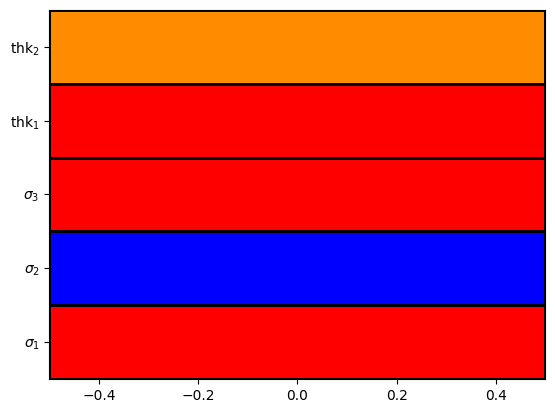

In [152]:
sensitivity_analysis(inv, m_true)

In [86]:
fig,axs = plt.subplots()

stdf

tensor([1.6717e+10, 1.2947e+00, 1.3404e+00, 4.6911e+00, 2.3704e+00],
       dtype=torch.float64)